***LAB 09***

**NAIVE BAYES CLASSIFIER**

Load Iris dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame
print(data.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


Load dataset from CSV (alternative)

In [3]:
#save the dataset to csv
data.to_csv('iris.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('iris.csv')
print(data.shape)

(150, 5)


Data preprocessing

In [4]:
#missing values
print(data.isnull().sum().sum())
data = data.fillna(data.median(numeric_only=True))

#encode categorical data if needed (iris is already numeric)
cat_cols = data.select_dtypes(include='object').columns
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

0


In [5]:
X = data.drop(columns='target')
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Train Gaussian Naive Bayes (features are continuous)

In [6]:
model = GaussianNB()
model.fit(X_train, y_train)

#predict on test set
y_pred = model.predict(X_test)

Evaluate performance

In [7]:
print('Accuracy =', accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy = 0.9666666666666667

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



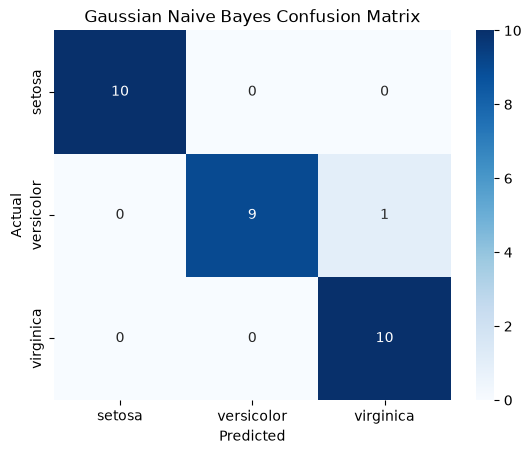

In [8]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes Confusion Matrix')
plt.show()

Test the model on new input / unseen data

In [9]:
#sepal length, sepal width, petal length, petal width (in cm)
new_data = pd.DataFrame([[5.1, 3.5, 1.4, 0.2],
                         [6.0, 2.9, 4.5, 1.5],
                         [6.9, 3.1, 5.8, 2.3]], columns=X.columns)

pred = model.predict(new_data)
proba = model.predict_proba(new_data)

for i in range(len(new_data)):
    print(new_data.iloc[i].values, '->', iris.target_names[pred[i]], '| probabilities =', proba[i].round(3))

[5.1 3.5 1.4 0.2] -> setosa | probabilities = [1. 0. 0.]
[6.  2.9 4.5 1.5] -> versicolor | probabilities = [0.    0.991 0.009]
[6.9 3.1 5.8 2.3] -> virginica | probabilities = [0. 0. 1.]


Naive Bayes applies Bayes' theorem, P(class | features) = P(features | class) x P(class) / P(features), and assumes that all features are independent given the class. Gaussian NB models every feature with a normal distribution for each class, which is why it is used for continuous data like Iris.

Even though petal length and petal width are correlated (so the independence assumption is not true), the model still gives high accuracy. The predict_proba output shows how confident the model is for each new flower.